<a href="https://colab.research.google.com/github/ViseshSaxena/ML-tutorial-9-SVM/blob/main/Credit_Card_Fraud_Detection_(ML_Project_1)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nelgiriyewithana/credit-card-fraud-detection-dataset-2023")

print("Path to dataset files:", path)

100%|██████████| 143M/143M [00:00<00:00, 156MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nelgiriyewithana/credit-card-fraud-detection-dataset-2023/versions/1


In [ ]:
import os
import pandas as pd

# List the contents of the downloaded directory
print(os.listdir(path))


['creditcard_2023.csv']


In [ ]:
# Assuming the primary dataset file is 'creditcard_2023.csv'
# Adjust the filename if it's different after inspecting the directory contents
dataset_file = os.path.join(path, 'creditcard_2023.csv')

# Load the dataset into a pandas DataFrame
df = pd.read_csv(dataset_file)
`
# Display the first 5 rows of the DataFrame
display(df.head())

,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,...,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,17982.10,0
1,1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,...,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,6531.37,0
2,2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,...,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,2513.54,0
3,3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,...,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,5384.44,0
4,4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,...,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,14278.97,0


Data Preprocessing

In [ ]:
import os
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import kagglehub

# --- Ensure 'path' is defined for data loading ---
# Download latest version of the dataset
path = kagglehub.dataset_download("nelgiriyewithana/credit-card-fraud-detection-dataset-2023")
print("Path to dataset files:", path)

# Re-define dataset_file path
dataset_file = os.path.join(path, 'creditcard_2023.csv')

# Reload the dataset to ensure df is available in the current context
df = pd.read_csv(dataset_file)

# Drop the 'id' column as determined in previous steps
df = df.drop('id', axis=1)
print("DataFrame reloaded and 'id' column dropped.")

# --- Feature Scaling and Data Splitting ---

# Separate features (X) and target (y)
X = df.drop('Class', axis=1)
y = df['Class']

# Scale the 'Amount' column
scaler = StandardScaler()
X['Amount'] = scaler.fit_transform(X[['Amount']])

print("Scaled 'Amount' column and separated features and target.")

# Display the first few rows of X after scaling
display(X.head())

# Split the data into training and testing sets
# We'll use a 70/30 split, which is a common practice.
# stratify=y ensures that both training and testing sets have a similar proportion of target classes.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"\nOriginal dataset shape: {df.shape}")
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

print("Data successfully split into training and testing sets.")

Using Colab cache for faster access to the 'credit-card-fraud-detection-dataset-2023' dataset.
Path to dataset files: /kaggle/input/credit-card-fraud-detection-dataset-2023
DataFrame reloaded and 'id' column dropped.
Scaled 'Amount' column and separated features and target.


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,0.637735,...,0.091202,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,0.858447
1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,0.529808,...,-0.233984,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,-0.796369
2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,0.690708,...,0.361652,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,-1.377011
3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,0.575231,...,-0.378223,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,-0.962119
4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,0.968046,...,0.247237,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,0.323285



Original dataset shape: (568630, 30)
Training features shape: (398041, 29)
Testing features shape: (170589, 29)
Training target shape: (398041,)
Testing target shape: (170589,)
Data successfully split into training and testing sets.


### Data Cleaning and Initial Exploration

First, let's check for missing values, data types, and duplicate rows to understand the dataset's integrity.

In [ ]:
# Check for missing values
print('Missing values in each column:')
display(df.isnull().sum())

Missing values in each column:


,0
id,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [ ]:
# Check data types and non-null counts
print('\nDataFrame Info:')
df.info()


DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568630 entries, 0 to 568629
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      568630 non-null  int64  
 1   V1      568630 non-null  float64
 2   V2      568630 non-null  float64
 3   V3      568630 non-null  float64
 4   V4      568630 non-null  float64
 5   V5      568630 non-null  float64
 6   V6      568630 non-null  float64
 7   V7      568630 non-null  float64
 8   V8      568630 non-null  float64
 9   V9      568630 non-null  float64
 10  V10     568630 non-null  float64
 11  V11     568630 non-null  float64
 12  V12     568630 non-null  float64
 13  V13     568630 non-null  float64
 14  V14     568630 non-null  float64
 15  V15     568630 non-null  float64
 16  V16     568630 non-null  float64
 17  V17     568630 non-null  float64
 18  V18     568630 non-null  float64
 19  V19     568630 non-null  float64
 20  V20     568630 non-null  float6

In [ ]:
# Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f'\nNumber of duplicate rows: {duplicate_rows}')


Number of duplicate rows: 0


Next, let's look at the descriptive statistics to get a summary of the numerical features.

In [ ]:
# Display descriptive statistics
print('\nDescriptive Statistics:')
display(df.describe())


Descriptive Statistics:


,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,568630.000000,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,...,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,568630.000000,568630.0
mean,284314.500000,-5.638058e-17,-1.319545e-16,-3.518788e-17,-2.879008e-17,7.997245e-18,-3.958636e-17,-3.198898e-17,2.109273e-17,3.998623e-17,...,4.758361e-17,3.948640e-18,6.194741e-18,-2.799036e-18,-3.178905e-17,-7.497417e-18,-3.598760e-17,2.609101e-17,12041.957635,0.5
std,164149.486121,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,...,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,6919.644449,0.5
min,0.000000,-3.495584e+00,-4.996657e+01,-3.183760e+00,-4.951222e+00,-9.952786e+00,-2.111111e+01,-4.351839e+00,-1.075634e+01,-3.751919e+00,...,-1.938252e+01,-7.734798e+00,-3.029545e+01,-4.067968e+00,-1.361263e+01,-8.226969e+00,-1.049863e+01,-3.903524e+01,50.010000,0.0
25%,142157.250000,-5.652859e-01,-4.866777e-01,-6.492987e-01,-6.560203e-01,-2.934955e-01,-4.458712e-01,-2.835329e-01,-1.922572e-01,-5.687446e-01,...,-1.664408e-01,-4.904892e-01,-2.376289e-01,-6.515801e-01,-5.541485e-01,-6.318948e-01,-3.049607e-01,-2.318783e-01,6054.892500,0.0
50%,284314.500000,-9.363846e-02,-1.358939e-01,3.528579e-04,-7.376152e-02,8.108788e-02,7.871758e-02,2.333659e-01,-1.145242e-01,9.252647e-02,...,-3.743065e-02,-2.732881e-02,-5.968903e-02,1.590123e-02,-8.193162e-03,-1.189208e-02,-1.729111e-01,-1.392973e-02,12030.150000,0.5
75%,426471.750000,8.326582e-01,3.435552e-01,6.285380e-01,7.070047e-01,4.397368e-01,4.977881e-01,5.259548e-01,4.729905e-02,5.592621e-01,...,1.479787e-01,4.638817e-01,1.557153e-01,7.007374e-01,5.500147e-01,6.728879e-01,3.340230e-01,4.095903e-01,18036.330000,1.0
max,568629.000000,2.229046e+00,4.361865e+00,1.412583e+01,3.201536e+00,4.271689e+01,2.616840e+01,2.178730e+02,5.958040e+00,2.027006e+01,...,8.087080e+00,1.263251e+01,3.170763e+01,1.296564e+01,1.462151e+01,5.623285e+00,1.132311e+02,7.725594e+01,24039.930000,1.0


### Dropping 'id' column and Analyzing Key Features

First, let's drop the 'id' column, as it is a unique identifier and not a predictive feature.

In [ ]:
# Drop the 'id' column
df = df.drop('id', axis=1)
print("Dropped 'id' column. DataFrame columns now:")
print(df.columns)

Dropped 'id' column. DataFrame columns now:
Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'],
      dtype='object')


Next, let's examine the distribution of the `Class` column to understand the balance between fraudulent and non-fraudulent transactions.

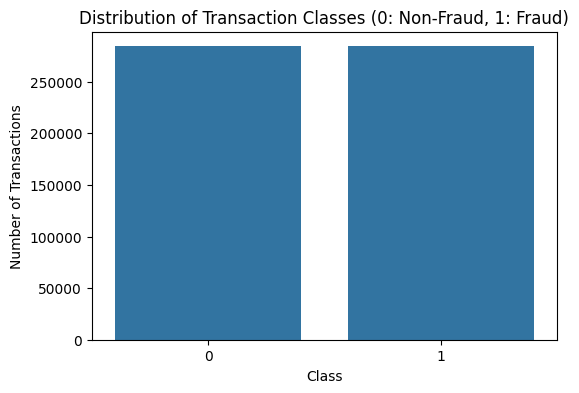


Class Distribution:


,count
Class,
0,284315
1,284315



Class Percentage:


,count
Class,
0,50.0
1,50.0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of the 'Class' column
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('Distribution of Transaction Classes (0: Non-Fraud, 1: Fraud)')
plt.xlabel('Class')
plt.ylabel('Number of Transactions')
plt.show()

# Display the count and percentage of each class
class_counts = df['Class'].value_counts()
print('\nClass Distribution:')
display(class_counts)
print('\nClass Percentage:')
display(class_counts / len(df) * 100)

Finally, let's look at the distribution of the `Amount` column.

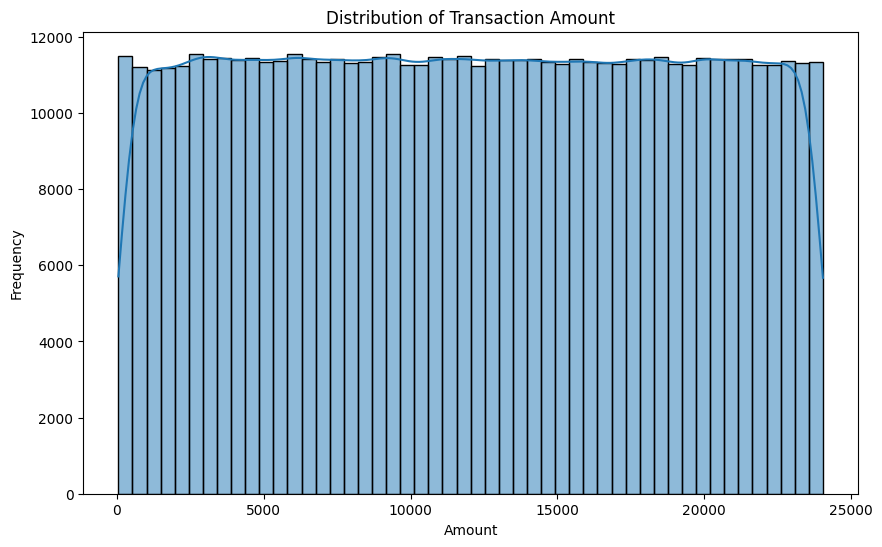


Descriptive Statistics for Amount:


,Amount
count,568630.000000
mean,12041.957635
std,6919.644449
min,50.010000
25%,6054.892500
50%,12030.150000
75%,18036.330000
max,24039.930000


In [ ]:
# Visualize the distribution of the 'Amount' column
plt.figure(figsize=(10, 6))
sns.histplot(df['Amount'], bins=50, kde=True)
plt.title('Distribution of Transaction Amount')
plt.xlabel('Amount')
plt.ylabel('Frequency')
plt.show()

# Display descriptive statistics for 'Amount'
print('\nDescriptive Statistics for Amount:')
display(df['Amount'].describe())

### Linear Regression

Although this is a classification problem, we can use Linear Regression to see how it fits the data. Note that for classification, Logistic Regression is generally preferred because it restricts outputs to between 0 and 1.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Initialize and train the Linear Regression model
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# Make predictions
y_pred_lin = lin_reg.predict(X_test)

# Evaluate using regression metrics
mse = mean_squared_error(y_test, y_pred_lin)
r2 = r2_score(y_test, y_pred_lin)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R-squared Score: {r2:.4f}")

# Display the first 10 predictions vs actual values
results_comparison = pd.DataFrame({'Actual': y_test[:10], 'Linear_Pred': y_pred_lin[:10]})
display(results_comparison)

Mean Squared Error: 0.0590
R-squared Score: 0.7639


,Actual,Linear_Pred
510747,1,0.506806
390373,1,0.577735
81077,0,0.230619
236854,0,0.138817
407198,1,0.888450
220669,0,-0.003748
152968,0,0.240481
501562,1,0.950422
270953,0,0.080612
478895,1,0.618064


As you can see, the Linear Regression model predicts values that aren't exactly 0 or 1. To use this for classification, we would need to set a 'threshold' (e.g., if prediction > 0.5, then Class 1).

### Feature Scaling and Data Splitting

Given the varying scales of the features, especially the `Amount` column compared to the V-features, it's crucial to perform feature scaling. This ensures that no single feature dominates the model training due to its magnitude. We will use `StandardScaler` for this purpose.

After scaling, we'll split the dataset into training and testing sets. This is a standard practice to evaluate the model's performance on unseen data, preventing overfitting and providing a more reliable estimate of its generalization ability.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop('Class', axis=1)
y = df['Class']

# Scale the 'Amount' column (and other features if needed, though V-features are already scaled-like)
# It's good practice to scale all features if their ranges vary significantly.
# Let's assume V1-V28 are already somewhat scaled, but Amount needs explicit scaling.
# For a real scenario, you might scale all features including V1-V28 if their ranges were not normalized.
scaler = StandardScaler()
X['Amount'] = scaler.fit_transform(X[['Amount']])

print("Scaled 'Amount' column and separated features and target.")

# Display the first few rows of X after scaling
display(X.head())

NameError: name 'df' is not defined

In [ ]:
# Split the data into training and testing sets
# We'll use a 70/30 split, which is a common practice.
# stratify=y ensures that both training and testing sets have a similar proportion of target classes.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Original dataset shape: {df.shape}")
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Testing target shape: {y_test.shape}")

print("Data successfully split into training and testing sets.")

### Support Vector Machine (SVM) Classifier

Now, we will train a Support Vector Machine classifier to detect fraud. Because the dataset has over 500,000 samples, a standard kernelized SVM can be very slow to train. Therefore, we will use `LinearSVC`, which scales much better to larger datasets.

Training variables not detected. Running preprocessing to reconstruct them...


100%|██████████| 143M/143M [00:01<00:00, 144MB/s]

Extracting files...


SVM Accuracy: 0.9630

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96     85295
           1       0.98      0.94      0.96     85294

    accuracy                           0.96    170589
   macro avg       0.96      0.96      0.96    170589
weighted avg       0.96      0.96      0.96    170589



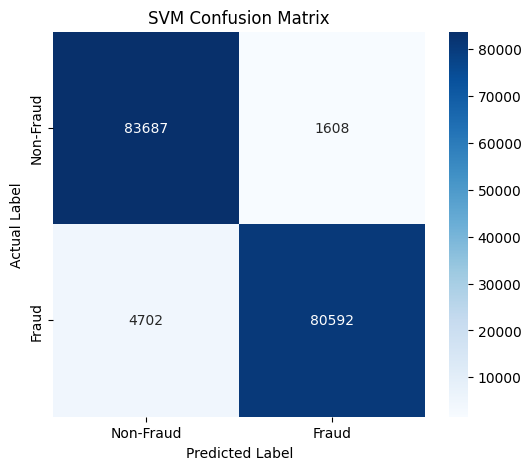

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure X_train, X_test, y_train, y_test are defined. If they are missing, run the preprocessing setup.
try:
    X_train, X_test, y_train, y_test
except NameError:
    print("Training variables not detected. Running preprocessing to reconstruct them...")
    import os
    import pandas as pd
    from sklearn.preprocessing import StandardScaler
    from sklearn.model_selection import train_test_split
    import kagglehub

    path = kagglehub.dataset_download("nelgiriyewithana/credit-card-fraud-detection-dataset-2023")
    dataset_file = os.path.join(path, 'creditcard_2023.csv')
    df = pd.read_csv(dataset_file)
    df = df.drop('id', axis=1)

    X = df.drop('Class', axis=1)
    y = df['Class']

    scaler = StandardScaler()
    X['Amount'] = scaler.fit_transform(X[['Amount']])
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Initialize and train the Linear SVM classifier
svm_model = LinearSVC(dual=False, random_state=42, max_iter=2000)
svm_model.fit(X_train, y_train)

# Make predictions on the testing set
y_pred_svm = svm_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred_svm)
print(f"SVM Accuracy: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred_svm))

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.title('SVM Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()